# putEMG-Force, all participants: timing, press detection, forecast and day-to-day transfer

Third stage. `hyser.ipynb` ran the tests on one participant and `hyser_multisubject.ipynb` on all 20 Hyser participants. This notebook repeats them on a second public dataset, recorded in another lab, with many presses from rest and two sessions per person.

**Data.** putEMG-Force (Poznan University of Technology, CC BY-NC 4.0): 44 participants, two sessions 7 to 82 days apart, with the electrodes placed again. 24 monopolar electrodes in three bands of eight around the right forearm (5120 Hz) and the force of each finger on a hand dynamometer (200 Hz). In each session the person follows a force target with the thumb, the index, the middle, the ring and little fingers together, or all fingers, in three recordings: `repeats_long` (55 presses), `sequential` (40) and `repeats_short` (25). Presses are steps of 1 or 3 s at 20 to 50% of maximum force, or slow ramps, separated by 3 to 11 s of rest. Download the force recordings with `python download_putemg_force.py` (about 20 GB) or set `PUTEMG_FORCE` to the folder that holds the `emg_force-*.hdf5` files.

Calibration uses `repeats_long` and testing uses `sequential` and `repeats_short` of the same session, unless stated otherwise. Features are causal, as in the Hyser notebooks, and the four finger forces are modelled separately.

1. **Timing (Figure 9).** The delay at which the sEMG predicts force best (as Figure 6).
2. **Press detection (Figure 10).** A causal detector that watches the sEMG continuously: how many presses it catches, how long before force onset, and how many false alarms it raises at rest, on the same day and in the next session.
3. **Forecast (Figure 11).** Error reduction against repeating the model's own estimate (as Figure 7).
4. **Day-to-day transfer (Figure 12).** A model calibrated in session 1 is tested in session 2 (as Figure 8).

Results for each person are cached in `results/putemg/`, so the notebook only processes new participants when it is run again.

In [1]:
import os, json, re, glob, warnings
from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt
from scipy.signal import butter, iirnotch, tf2sos, sosfilt
from scipy.stats import wilcoxon
from sklearn.decomposition import PCA
from IPython.display import Image, display
warnings.filterwarnings("ignore")
%matplotlib inline

REPO_DIR = Path.cwd()  # run the notebook from the repository folder
PUTEMG_FORCE = os.environ.get("PUTEMG_FORCE", "data/putemg_force")
FIG_DIR, RES_DIR = REPO_DIR / "figures", REPO_DIR / "results"
CACHE_DIR = RES_DIR / "putemg"
for d in (FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
FS_F, FS_D = 100, 1000                    # Hz: features and force for the models; detector
FINGERS = ["thumb", "index", "middle", "ring+little"]
SENSORS = [[0, 1], [2, 3], [4, 5], [6, 7, 8, 9]]  # FORCE_1-10: two strain gauges per finger, four for ring and little
PRESS_TYPES = FINGERS + ["all"]
KINDS = ("repeats_long", "sequential", "repeats_short")
START, HMAX = 100, 20                     # skip the first 1 s; keep 200 ms at the end for future targets
HORIZONS_MS = [30, 50, 70, 100, 150, 200]
LAGS = (0, 3, 6)
K_PCA = 16
ALPHAS = [1.0, 10.0, 100.0, 1000.0]
WIN_MS, DET_WIN_MS = 50, 20
PHASES = ["rising", "steady", "falling"]
MODELS = ["EMG forecast", "baseline 1: own estimate", "baseline 2: measured force"]
RECAL_S = (20, 40, 60, 120)               # seconds of the new session used for calibration
DET_K = (3, 5, 8)                         # detector threshold: rest mean + k SD
DET_CONF_MS = (10, 25, 50)                # confirmation time
DET_REARM_MS = 200                        # the detector fires again only after this long below threshold
N_BOOT, BLOCK = 500, 100
SEED = 7
CACHE_VERSION = 2
DELAYS_MS = list(range(-100, 310, 10))   # delays from the sEMG features to force

BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=900))
    print("saved", path.relative_to(REPO_DIR))


setup()

## Reading and features

Each recording holds the sEMG, the ten strain gauges and the force target, with the sensor offsets already removed. The force of a finger is the mean of its gauges. The sEMG is band-pass filtered (20–450 Hz) with notches at the 50 Hz mains harmonics, all causal, and summarised per electrode as the log RMS over a trailing window: 50 ms every 10 ms for the models, 20 ms every 1 ms for the detector.

In [3]:
def participants():
    return sorted({int(os.path.basename(f).split("-")[1]) for f in glob.glob(os.path.join(PUTEMG_FORCE, "emg_force-*.hdf5"))})


def duration_s(path):
    with h5py.File(path, "r") as h:
        tb = h["data/table"]
        return float(tb[tb.shape[0] - 1]["index"] - tb[0]["index"])


def sessions(s):
    """Recordings of participant s by session, in date order. When a recording was repeated, the last one is used.
    Recordings shorter than 60 s are left out; a session needs `repeats_long` and `sequential`."""
    out = {}
    for f in sorted(glob.glob(os.path.join(PUTEMG_FORCE, f"emg_force-{s:02d}-*.hdf5"))):
        p = os.path.basename(f).split("-")
        if p[2] in KINDS and duration_s(f) >= 60:
            out.setdefault("-".join(p[3:6]), {})[p[2]] = f
    return [out[d] for d in sorted(out) if all(k in out[d] for k in KINDS[:2])]


def read_record(path):
    """Time (s), 24 sEMG channels, 4 finger forces and 4 force targets (sensor units)."""
    with h5py.File(path, "r") as h:
        tb = h["data/table"]
        names = [m.decode() for m in re.findall(rb"V([^\n]+)\np\d+", bytes(tb.attrs["values_block_3_kind"]))]
        n = tb.shape[0]
        t, V = np.empty(n), np.empty((n, len(names)), np.float32)
        for i in range(0, n, 200000):
            a = tb[i:i + 200000]
            t[i:i + len(a)], V[i:i + len(a)] = a["index"], a["values_block_3"]
    col = {nm: k for k, nm in enumerate(names)}
    emg = V[:, [col[f"EMG_{k}"] for k in range(1, 25)]]
    gauges = V[:, [col[f"FORCE_{k}"] for k in range(1, 11)]].astype(np.float64)
    force = np.stack([gauges[:, g].mean(1) for g in SENSORS], 1)
    target = V[:, [col[f"TRAJ_{k}"] for k in range(1, 5)]].astype(np.float64)
    return t, emg, force, target


def emg_sos(fs):
    """Causal band-pass 20-450 Hz and notches at the 50 Hz mains harmonics."""
    sos = butter(4, [20, 450], btype="band", fs=fs, output="sos")
    for k in range(50, 451, 50):
        b, a = iirnotch(k, 30, fs)
        sos = np.vstack([sos, tf2sos(b, a)])
    return sos


def trailing_log_rms(c, idx, w):
    lo = np.clip(idx - w, 0, None)
    return np.log(np.sqrt(np.maximum(c[idx] - c[lo], 0) / np.maximum(idx - lo, 1)[:, None]) + 1e-3)


def features(t, emg, force, target, qc=False):
    """Per-electrode causal features at 100 Hz (L) and 1 kHz (D): the value at time tau uses sEMG samples up to tau only.
    Forces and targets are taken at the same times."""
    fs = 1 / np.median(np.diff(t))
    n = len(t)
    idx = {r: np.clip(np.floor(np.arange(int(np.floor((n - 1) / fs * r))) / r * fs).astype(int) + 1, 1, n) for r in (FS_F, FS_D)}
    sos = emg_sos(fs)
    L = np.empty((len(idx[FS_F]), 24), np.float32)
    D = np.empty((len(idx[FS_D]), 24), np.float32)
    kurt = np.zeros(24)
    for ch in np.array_split(np.arange(24), 6):
        x = sosfilt(sos, emg[:, ch].astype(np.float64), axis=0)
        if qc:
            z = (x[int(fs):] - x[int(fs):].mean(0)) / (x[int(fs):].std(0) + 1e-9)
            kurt[ch] = np.mean(z ** 4, 0)
        c = np.vstack([np.zeros((1, len(ch))), np.cumsum(x ** 2, 0)])
        L[:, ch] = trailing_log_rms(c, idx[FS_F], int(round(WIN_MS / 1000 * fs)))
        D[:, ch] = trailing_log_rms(c, idx[FS_D], int(round(DET_WIN_MS / 1000 * fs)))
    R = dict(L=L, D=D, F=force[idx[FS_F] - 1], F1k=force[idx[FS_D] - 1].astype(np.float32))
    R["P"] = force_onsets(R["F1k"], press_list(target[idx[FS_D] - 1]))
    if qc:
        R["qc"] = electrode_qc(L, kurt)
    return R


def load(path, qc=False):
    return features(*read_record(path), qc=qc)

**Electrode check** (session 1, calibration recording): electrodes with an abnormal amplitude, spikes, or an envelope unlike that of their neighbours (the next electrodes in the same band and the same position in the next bands) are excluded in both sessions, as in a device that cannot re-check them.

**Presses and force onsets.** Presses come from the force target. Slow ramps are kept out of the timing and detection tests, because their onset is not defined by a step. The force onset of a step press is the last time the force of the pressing finger(s) was at rest before it rose to half of the press: rest level and noise are measured 0.8 to 1.6 s after the previous press, and the threshold is the larger of 5 SD and 2% of the press. A press whose force had already left rest when that window ended is not used.

In [4]:
def electrode_qc(L, kurt):
    lr = np.median(L, 0)
    flags = {}

    def robust_z(v):
        return (v - np.median(v)) / (1.4826 * np.median(np.abs(v - np.median(v))) + 1e-9)

    zr, zk = robust_z(lr), robust_z(np.log(kurt + 1e-9))
    for k in range(24):
        why = []
        if abs(zr[k]) > 5: why.append("amplitude")
        if zk[k] > 4 and kurt[k] > 50: why.append("spikes")
        if why: flags[k + 1] = why
    env = np.exp(L[START:].astype(np.float64))
    for k in range(24):
        b, p = divmod(k, 8)
        nb = [8 * b + (p + 1) % 8, 8 * b + (p - 1) % 8] + [8 * bb + p for bb in (b - 1, b + 1) if 0 <= bb < 3]
        nb = [j for j in nb if j + 1 not in flags]
        if nb and np.corrcoef(env[:, k], np.median(env[:, nb], 1))[0, 1] < 0.3:
            flags.setdefault(k + 1, []).append("unlike neighbours")
    return flags


def press_list(target):
    on = target > 0
    d = np.diff(np.r_[0, on.any(1).astype(np.int8), 0])
    out = []
    for s, e in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)):
        f = np.flatnonzero(on[s:e].any(0))
        tr = target[s:e, f[0]]
        out.append(dict(start=int(s), end=int(e), type="all" if len(f) > 1 else FINGERS[f[0]], fingers=f.tolist(),
                        ramp=bool(np.argmax(tr >= 0.95 * tr.max()) > 0.2 * FS_D)))
    return out


def force_onsets(F, P):
    prev_end = 0
    for p in P:
        b0, b1 = prev_end + 800, prev_end + 1600
        prev_end = p["end"]
        p["onset"] = None
        if p["ramp"] or b1 >= p["start"] - 500 or p["end"] - p["start"] < 600:
            continue
        f = F[:, p["fingers"]].sum(1).astype(np.float64)
        base, sd = np.median(f[b0:b1]), f[b0:b1].std()
        amp = np.median(f[p["start"] + 300:p["end"]]) - base
        if amp <= 0 or amp <= 10 * sd:
            continue
        up = np.flatnonzero(f[b1:p["end"]] - base > 0.5 * amp)
        if not len(up):
            continue
        t50 = b1 + up[0]
        low = np.flatnonzero(f[b1:t50] - base <= max(5 * sd, 0.02 * amp))
        if len(low):
            p["onset"] = int(b1 + low[-1] + 1)
    return P


def rest_mask(n, P):
    """Rest: from 0.8 s after a press to 0.3 s before the next force onset (1.5 s before the target of presses without one).
    The first 2 s of a recording are left out."""
    m = np.zeros(n, bool)
    prev = 2000
    for p in P:
        nxt = p["onset"] - 300 if p["onset"] is not None else p["start"] - 1500
        if nxt > prev:
            m[prev:nxt] = True
        prev = p["end"] + 800
    m[prev:] = True
    return m

## Check: the features do not look ahead

At three random times the sEMG after *t* is set to zero and the features are recomputed. A causal feature at *t* must not change.

In [5]:
SUBJECTS = participants()
print(f"{len(SUBJECTS)} participants found")
assert SUBJECTS, "no putEMG-Force recordings found: run download_putemg_force.py or set PUTEMG_FORCE"

t_, emg_, force_, target_ = read_record(sessions(SUBJECTS[0])[0]["sequential"])
full = features(t_, emg_, force_, target_)
fs_ = 1 / np.median(np.diff(t_))
LOOKAHEAD = dict(model_features=0.0, detector_features=0.0)
for k in np.random.default_rng(SEED).integers(500, len(full["L"]) - 500, 3):
    cut = int(np.floor(k / FS_F * fs_)) + 1          # sEMG samples available at feature sample k
    e2 = emg_.copy()
    e2[cut:] = 0
    part = features(t_, e2, force_, target_)
    LOOKAHEAD["model_features"] = max(LOOKAHEAD["model_features"], float(np.abs(part["L"][k] - full["L"][k]).max()))
    kd = k * FS_D // FS_F
    LOOKAHEAD["detector_features"] = max(LOOKAHEAD["detector_features"], float(np.abs(part["D"][kd] - full["D"][kd]).max()))
for k, v in LOOKAHEAD.items():
    print(f"{k:18s} largest change when the future is removed: {v:.1e} (log units)")
assert max(LOOKAHEAD.values()) < 1e-6
del t_, emg_, force_, target_, full, part, e2

44 participants found


model_features     largest change when the future is removed: 0.0e+00 (log units)
detector_features  largest change when the future is removed: 0.0e+00 (log units)


## Models

As in the Hyser notebooks: z-score and PCA (16 components) fitted on the calibration samples, lags of 0, 30 and 60 ms, and ridge regression whose penalty is chosen by blocked cross-validation inside the calibration data. The ridge is solved in closed form from the calibration statistics, which gives the same solution as scikit-learn's `Ridge` and lets all horizons share one fit.

In [6]:
class FrontEnd:
    """z-score and PCA, both fitted on calibration samples."""
    def fit(self, L, idx):
        self.mu, self.sd = L[idx].mean(0), L[idx].std(0) + 1e-9
        self.pca = PCA(n_components=K_PCA, random_state=0).fit((L[idx] - self.mu) / self.sd)
        self.scale = np.sqrt(self.pca.explained_variance_) + 1e-9
        return self

    def transform(self, L):
        return self.pca.transform((L - self.mu) / self.sd) / self.scale

    def renormalised(self, L, idx):
        """The same model with the sEMG normalisation measured on new samples (no force needed)."""
        fe = FrontEnd()
        fe.pca, fe.scale = self.pca, self.scale
        fe.mu, fe.sd = L[idx].mean(0), L[idx].std(0) + 1e-9
        return fe


def shift(Z, L):
    out = np.zeros_like(Z)
    if L == 0:
        return Z.copy()
    out[L:] = Z[:-L]
    return out


def design(Z):
    return np.hstack([shift(Z, L) for L in LAGS])


def eval_idx(n, end=HMAX):
    return np.arange(START, n - end)


def _stats(X, Y):
    return [X.T @ X, X.sum(0), X.T @ Y, Y.sum(0), len(X)]


def _solve(st, a):
    G, xs, XY, ys, n = st
    mx, my = xs / n, ys / n
    W = np.linalg.solve(G - n * np.outer(mx, mx) + a * np.eye(len(mx)), XY - n * np.outer(mx, my))
    return W, my - mx @ W


def ridge(X, y, idx, shifts, gap):
    """Ridge with intercept predicting y[t + d] for each d in `shifts` from X[t], t in idx. The penalty of each target
    is chosen by blocked cross-validation (5 blocks; `gap` samples around the validation block are left out)."""
    Xi = X[idx]
    Y = np.stack([y[idx + d] for d in shifts], 1)
    tot = _stats(Xi, Y)
    sse = np.zeros((len(ALPHAS), len(shifts)))
    for b in np.array_split(np.arange(len(idx)), 5):
        out = (idx >= idx[b[0]] - gap) & (idx <= idx[b[-1]] + gap)
        tr = [u - v for u, v in zip(tot, _stats(Xi[out], Y[out]))]
        for i, a in enumerate(ALPHAS):
            W, c = _solve(tr, a)
            sse[i] += ((Xi[b] @ W + c - Y[b]) ** 2).sum(0)
    best = np.argmin(sse, 0)
    W, c = np.zeros((X.shape[1], len(shifts))), np.zeros(len(shifts))
    for i in set(best.tolist()):
        Wi, ci = _solve(tot, ALPHAS[i])
        W[:, best == i], c[best == i] = Wi[:, best == i], ci[best == i]
    return W, c


def calib(recs, sec=None):
    """Concatenate calibration recordings (optionally only the first `sec` seconds of the last one)."""
    L, F, idx, off = [], [], [], 0
    for k, r in enumerate(recs):
        Lr, Fr, ir = r["L"], r["F"], eval_idx(len(r["L"]))
        if sec is not None and k == len(recs) - 1:
            ir = ir[ir < START + sec * FS_F]
            Lr, Fr = Lr[:ir[-1] + HMAX + 1], Fr[:ir[-1] + HMAX + 1]
        L.append(Lr); F.append(Fr); idx.append(ir + off); off += len(Lr)
    return np.vstack(L), np.vstack(F), np.concatenate(idx)


def r2(p, y):
    return float(1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2))


def rest_level(r):
    """Force of each finger at rest in a recording (median over the rest periods)."""
    m = rest_mask(len(r["F1k"]), r["P"])[::FS_D // FS_F][:len(r["F"])]
    return np.median(r["F"][m], 0)


PH_CODE = {"rest": 0, "rising": 1, "steady": 2, "falling": 3}


def phase_labels(y, rest, ref):
    """Evaluation only: rising / falling / steady / rest from the measured force (centred smoothing)."""
    a = np.abs(y - rest)
    sm = np.convolve(a, np.ones(5) / 5, mode="same")
    d = np.zeros_like(sm)
    d[5:-5] = sm[10:] - sm[:-10]
    thr, near = 0.15 * ref, 0.10 * ref
    lab = np.full(len(y), PH_CODE["steady"], np.int8)
    lab[d > thr] = PH_CODE["rising"]
    lab[d < -thr] = PH_CODE["falling"]
    lab[(np.abs(d) <= thr) & (sm <= near)] = PH_CODE["rest"]
    return lab

## Analysis for one person

**Delay of best prediction.** For each finger, ridge models from the causal sEMG features at *t* to force at *t* + *d* (*d* from −100 to 300 ms), calibrated on `repeats_long` and scored (R²) on `sequential` and `repeats_short`. The profile of a person is the mean over the four fingers and the two sessions.

**Press detection.** The detector z-scores each electrode's 20 ms log RMS against its rest level in the calibration recording and follows the mean of the three most active electrodes. It fires when that value stays above *k* for a confirmation time, and fires again only after 200 ms below *k*. A press is caught when the detector fires between 300 ms before its force onset and the end of the press; the warning time is the force onset minus the first firing time (positive = before force). A firing at rest is a false alarm. Same day: rest levels from the same session. Next session: rest levels from session 1, applied to session 2 without any update.

**Forecast.** Gain = error of baseline 1 minus error of the sEMG forecast, in points of a typical press of each finger, pooled over the four fingers and both sessions, with a moving-block bootstrap interval within the person (1 s blocks, the same resample for every model).

**Day-to-day transfer.** Test: session 2, `repeats_short`. Calibration: session 1 (`repeats_long` and `sequential`), as it is, or with the sEMG normalisation updated on the first seconds of session 2 `sequential` (no force needed), or with those seconds with force (together with session 1, or alone); `sequential` cycles through all five press types every 20 to 60 s. Reference: the same model calibrated on session 2 `repeats_long` and `sequential`. Score: R² of the finger force estimate (h = 0) and of the forecast at 100 ms, mean over the four fingers.

In [7]:
H_ALL = [0] + [hm // 10 for hm in HORIZONS_MS]


def delay_profile(cal, tests):
    shifts = [d // 10 for d in DELAYS_MS]
    hi = max(shifts)
    ic = eval_idx(len(cal["L"]), hi)
    fe = FrontEnd().fit(cal["L"], ic)
    Xc = design(fe.transform(cal["L"]))
    Xt = [design(fe.transform(r["L"])) for r in tests]
    it = [eval_idx(len(r["L"]), hi) for r in tests]
    prof = np.zeros((len(FINGERS), len(shifts)))
    for j in range(len(FINGERS)):
        W, c = ridge(Xc, cal["F"][:, j], ic, shifts, 50 + hi)
        P = np.vstack([X[i] @ W + c for X, i in zip(Xt, it)])
        Y = np.vstack([np.stack([r["F"][i + d, j] for d in shifts], 1) for r, i in zip(tests, it)])
        prof[j] = 1 - ((P - Y) ** 2).sum(0) / ((Y - Y.mean(0)) ** 2).sum(0)
    return prof


def forecast(cal, tests):
    """Squared errors (4 fingers x time, scaled by each finger's typical press) and phase codes, test recordings joined."""
    ic = eval_idx(len(cal["L"]))
    fe = FrontEnd().fit(cal["L"], ic)
    Xc = design(fe.transform(cal["L"]))
    rest_c = rest_level(cal)
    E = {(nm, hm): [] for nm in MODELS for hm in HORIZONS_MS}
    LAB = {hm: [] for hm in HORIZONS_MS}
    for r in tests:
        Xt, it, rest_t = design(fe.transform(r["L"])), eval_idx(len(r["L"])), rest_level(r)
        err = {k: np.zeros((len(FINGERS), len(it))) for k in E}
        lab = {hm: np.zeros((len(FINGERS), len(it)), np.int8) for hm in HORIZONS_MS}
        for j in range(len(FINGERS)):
            yc, yt = cal["F"][:, j], r["F"][:, j]
            W, c = ridge(Xc, yc, ic, H_ALL, 50 + HMAX)
            P = Xt @ W + c
            scale = np.percentile(np.abs(yt[it] - rest_t[j]), 95)
            ph = phase_labels(yt, rest_t[j], np.percentile(np.abs(yc[ic] - rest_c[j]), 95))
            for k, hm in enumerate(HORIZONS_MS):
                h = hm // 10
                lab[hm][j] = ph[it + h]
                for nm, v in zip(MODELS, [P[:, k + 1], P[:, 0], yt]):
                    err[(nm, hm)][j] = ((v[it] - yt[it + h]) / scale) ** 2
        for k in E:
            E[k].append(err[k])
        for hm in HORIZONS_MS:
            LAB[hm].append(lab[hm])
    return {k: np.hstack(v) for k, v in E.items()}, {k: np.hstack(v) for k, v in LAB.items()}


def gains(E, LAB, rng):
    """Gain of the sEMG forecast over baselines 1 and 2 (pooled over fingers), with a moving-block bootstrap interval,
    and the gain for each finger (estimate only)."""
    N = LAB[HORIZONS_MS[0]].shape[1]
    starts = rng.integers(0, N, (N_BOOT, N // BLOCK))

    def rmse(nm, hm, p, j=None):
        m = LAB[hm] == PH_CODE[p]
        e = E[(nm, hm)]
        if j is not None:
            return 100 * np.sqrt(e[j][m[j]].mean()) if m[j].any() else np.nan, None
        v, c = np.where(m, e, 0).sum(0), m.sum(0)
        cv, cc = np.r_[0, np.cumsum(np.r_[v, v[:BLOCK]])], np.r_[0, np.cumsum(np.r_[c, c[:BLOCK]])]
        bv, bc = (cv[starts + BLOCK] - cv[starts]).sum(1), (cc[starts + BLOCK] - cc[starts]).sum(1)
        return 100 * np.sqrt(v.sum() / c.sum()), 100 * np.sqrt(bv / np.maximum(bc, 1))

    out = {}
    for b in MODELS[1:]:
        out[b] = {}
        for p in PHASES:
            est, lo, hi = [], [], []
            for hm in HORIZONS_MS:
                (eb, bb), (ef, bf) = rmse(b, hm, p), rmse(MODELS[0], hm, p)
                est.append(round(float(eb - ef), 2))
                lo.append(round(float(np.percentile(bb - bf, 2.5)), 2)); hi.append(round(float(np.percentile(bb - bf, 97.5)), 2))
            out[b][p] = dict(gain=est, ci95=[[a, c] for a, c in zip(lo, hi)],
                             per_finger={f: [round(float(rmse(b, hm, p, j)[0] - rmse(MODELS[0], hm, p, j)[0]), 2) for hm in HORIZONS_MS]
                                         for j, f in enumerate(FINGERS)})
    return out


def det_stat(D, mu, sd):
    z = (D - mu) / sd
    return np.sort(z, 1)[:, -3:].mean(1)


def fire_times(stat, k, conf):
    above = np.r_[False, stat > k, False]
    d = np.diff(above.astype(np.int8))
    st, en = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    fires, i = [], 0
    while i < len(st):
        j = i
        while j + 1 < len(st) and st[j + 1] - en[j] < DET_REARM_MS:
            j += 1
        for r in range(i, j + 1):
            if en[r] - st[r] >= conf:
                fires.append(st[r] + conf - 1)
                break
        i = j + 1
    return np.array(fires, int)


def detection(cal, tests):
    """Counts for each detector setting: presses caught by type, warning times, false alarms and minutes at rest."""
    rm = rest_mask(len(cal["D"]), cal["P"])
    mu, sd = cal["D"][rm].mean(0), cal["D"][rm].std(0) + 1e-6
    stats = [det_stat(r["D"], mu, sd) for r in tests]
    out = {}
    for k in DET_K:
        for conf in DET_CONF_MS:
            o = dict(caught={t: 0 for t in PRESS_TYPES}, presses={t: 0 for t in PRESS_TYPES}, before_force=0, lead_ms=[],
                     window_s=0.0, false_alarms=0, rest_min=0.0)
            for r, st in zip(tests, stats):
                fires = fire_times(st, k, conf)
                m = rest_mask(len(st), r["P"])
                o["false_alarms"] += int(m[fires].sum())
                o["rest_min"] += m.sum() / FS_D / 60
                for p in r["P"]:
                    if p["onset"] is None:
                        continue
                    o["presses"][p["type"]] += 1
                    o["window_s"] += (p["end"] - p["onset"] + 300) / FS_D
                    w = fires[(fires >= p["onset"] - 300) & (fires <= p["end"])]
                    if len(w):
                        o["caught"][p["type"]] += 1
                        o["lead_ms"].append(int(p["onset"] - w[0]))
                        o["before_force"] += int(w[0] <= p["onset"])
            out[f"k{k}_c{conf}"] = o
    return out


def merge_counts(a, b):
    out = {}
    for key in a:
        out[key] = {f: ({t: a[key][f][t] + b[key][f][t] for t in PRESS_TYPES} if isinstance(a[key][f], dict) else a[key][f] + b[key][f])
                    for f in a[key]}
    return out


def summarise(counts):
    out = {}
    for key, o in counts.items():
        n, c = sum(o["presses"].values()), sum(o["caught"].values())
        out[key] = dict(caught=round(c / n, 3) if n else None, caught_before_force=round(o["before_force"] / n, 3) if n else None,
                        caught_by_type={t: round(o["caught"][t] / o["presses"][t], 3) if o["presses"][t] else None for t in PRESS_TYPES},
                        presses=n, warning_ms_median=float(np.median(o["lead_ms"])) if o["lead_ms"] else None,
                        false_alarms_per_min=round(o["false_alarms"] / o["rest_min"], 2) if o["rest_min"] else None,
                        rest_min=round(o["rest_min"], 1), window_s_mean=round(o["window_s"] / n, 2) if n else None)
    return out


def transfer(S1, S2):
    """Session 1 -> session 2: R2 at h = 0 and 100 ms for each calibration strategy, mean over the four fingers."""
    test = S2["repeats_short"]
    it = eval_idx(len(test["L"]))
    L1, F1, i1 = calib([S1["repeats_long"], S1["sequential"]])
    L2, F2, i2 = calib([S2["repeats_long"], S2["sequential"]])
    seq2 = S2["sequential"]
    fe1, fe2 = FrontEnd().fit(L1, i1), FrontEnd().fit(L2, i2)
    X1, X2 = design(fe1.transform(L1)), design(fe2.transform(L2))
    shifts = [0, 10]
    R = {}

    def add(name, P):
        for k, hm in enumerate((0, 100)):
            R.setdefault(f"h{hm}", {}).setdefault(name, []).append(r2(P[it, k], yt_shift[k]))

    for j in range(len(FINGERS)):
        yt_shift = [test["F"][it + d, j] for d in shifts]
        W, c = ridge(X2, F2[:, j], i2, shifts, 50 + HMAX)
        add("same_day", design(fe2.transform(test["L"])) @ W + c)
        W, c = ridge(X1, F1[:, j], i1, shifts, 50 + HMAX)
        add("previous_day", design(fe1.transform(test["L"])) @ W + c)
        for sec in RECAL_S:
            ik = eval_idx(len(seq2["L"]))
            ik = ik[ik < START + sec * FS_F]
            add(f"renormalised_{sec}s", design(fe1.renormalised(seq2["L"], ik).transform(test["L"])) @ W + c)
            Lb, Fb, ib = calib([S1["repeats_long"], S1["sequential"], seq2], sec)
            feb = FrontEnd().fit(Lb, ib)
            Wb, cb = ridge(design(feb.transform(Lb)), Fb[:, j], ib, shifts, 50 + HMAX)
            add(f"both_days_{sec}s", design(feb.transform(test["L"])) @ Wb + cb)
            Ln, Fn, inew = calib([seq2], sec)
            fen = FrontEnd().fit(Ln, inew)
            Wn, cn = ridge(design(fen.transform(Ln)), Fn[:, j], inew, shifts, 50 + HMAX)
            add(f"new_day_only_{sec}s", design(fen.transform(test["L"])) @ Wn + cn)
    return {h: {k: round(float(np.mean(v)), 3) for k, v in d.items()} for h, d in R.items()}, \
           {h: {k: [round(float(x), 3) for x in v] for k, v in d.items()} for h, d in R.items()}


def keep_electrodes(r, keep):
    r["L"], r["D"] = r["L"][:, keep], r["D"][:, keep]
    return r


def analyse(s):
    path = CACHE_DIR / f"subject{s:02d}.json"
    if path.exists():
        r = json.loads(path.read_text())
        if r.get("version") == CACHE_VERSION:
            return r
    S = sessions(s)
    if not S:
        return None
    rng = np.random.default_rng(SEED + s)
    first = load(S[0]["repeats_long"], qc=True)
    keep = np.array([k + 1 not in first["qc"] for k in range(24)])
    res = dict(version=CACHE_VERSION, subject=s, sessions=len(S), excluded_electrodes={str(k): v for k, v in first["qc"].items()})
    REC = []
    for i, sess in enumerate(S[:2]):
        REC.append({kind: keep_electrodes(first if (i == 0 and kind == "repeats_long") else load(sess[kind]), keep)
                    for kind in KINDS if kind in sess})
    res["presses"] = [{kind: dict(total=len(R[kind]["P"]), with_force_onset=sum(p["onset"] is not None for p in R[kind]["P"]))
                       for kind in R} for R in REC]
    tests = [[R[k] for k in KINDS[1:] if k in R] for R in REC]
    prof = [delay_profile(R["repeats_long"], T) for R, T in zip(REC, tests)]
    res["delay_profile_r2"] = [round(float(v), 4) for v in np.mean([p.mean(0) for p in prof], 0)]
    res["delay_profile_r2_by_finger"] = {f: [round(float(v), 4) for v in np.mean([p[j] for p in prof], 0)] for j, f in enumerate(FINGERS)}
    E, LAB = {}, {}
    for R, T in zip(REC, tests):
        e, lab = forecast(R["repeats_long"], T)
        for k, v in e.items():
            E[k] = np.hstack([E[k], v]) if k in E else v
        for k, v in lab.items():
            LAB[k] = np.hstack([LAB[k], v]) if k in LAB else v
    res["gain_points"] = gains(E, LAB, rng)
    del E, LAB
    same = [detection(R["repeats_long"], T) for R, T in zip(REC, tests)]
    res["detection_same_day"] = summarise(same[0] if len(same) == 1 else merge_counts(*same))
    res["detection_next_session"] = None
    res["transfer_r2"] = res["transfer_r2_by_finger"] = None
    if len(REC) == 2:
        res["detection_next_session"] = summarise(detection(REC[0]["repeats_long"], tests[1]))
        if "repeats_short" in REC[1]:
            res["transfer_r2"], res["transfer_r2_by_finger"] = transfer(REC[0], REC[1])
    path.write_text(json.dumps(res))
    return res

## Run all participants

In [8]:
RES = {}
for s in SUBJECTS:
    r = analyse(s)
    if r is None:
        print(f"participant {s:02d}: recordings not found")
        continue
    RES[s] = r
    best = DELAYS_MS[int(np.argmax(r["delay_profile_r2"]))]
    g = r["gain_points"]["baseline 1: own estimate"]["rising"]["gain"][HORIZONS_MS.index(100)]
    d = r["detection_same_day"]["k5_c25"]
    tr = r["transfer_r2"]["h0"] if r["transfer_r2"] else None
    print(f"participant {s:02d}: {len(r['excluded_electrodes'])} electrodes excluded | best delay {best} ms | "
          f"presses caught {d['caught']:.0%}, false alarms {d['false_alarms_per_min']}/min | gain at 100 ms, force rising {g:+.1f} | "
          f"R2 next session {tr['previous_day'] if tr else '-'} (same day {tr['same_day'] if tr else '-'})")
print(f"\n{len(RES)} participants")

participant 03: 0 electrodes excluded | best delay 190 ms | presses caught 40%, false alarms 0.8/min | gain at 100 ms, force rising -0.2 | R2 next session -1.167 (same day 0.175)
participant 04: 1 electrodes excluded | best delay 90 ms | presses caught 43%, false alarms 0.77/min | gain at 100 ms, force rising +0.7 | R2 next session -1.65 (same day 0.357)
participant 05: 0 electrodes excluded | best delay 140 ms | presses caught 14%, false alarms 0.0/min | gain at 100 ms, force rising +0.2 | R2 next session -10.728 (same day 0.426)
participant 06: 2 electrodes excluded | best delay 60 ms | presses caught 41%, false alarms 0.86/min | gain at 100 ms, force rising +0.2 | R2 next session -9.741 (same day 0.542)
participant 07: 1 electrodes excluded | best delay 70 ms | presses caught 30%, false alarms 0.62/min | gain at 100 ms, force rising +0.4 | R2 next session -1.588 (same day 0.538)
participant 08: 1 electrodes excluded | best delay 90 ms | presses caught 77%, false alarms 1.79/min | ga

## Figure 9 · Timing across participants

**a.** R² of each person relative to their best delay (thin lines), median in black. **b.** R² at 0 ms and at each person's best delay. Mean over the four fingers and both sessions.

delay of best prediction (44 participants): median 100 ms, IQR [90, 140] ms, range 50 to 300 ms; after 0 ms in 44 of 44
R2 at 0 ms: median 0.40; at the best delay: median 0.41

by finger (people whose best R2 for that finger is at least 0.2):
  thumb        best R2 median 0.29 | 31 people with R2 >= 0.2, their best delay median 70 ms
  index        best R2 median 0.32 | 35 people with R2 >= 0.2, their best delay median 110 ms
  middle       best R2 median 0.34 | 39 people with R2 >= 0.2, their best delay median 120 ms
  ring+little  best R2 median 0.67 | 43 people with R2 >= 0.2, their best delay median 140 ms


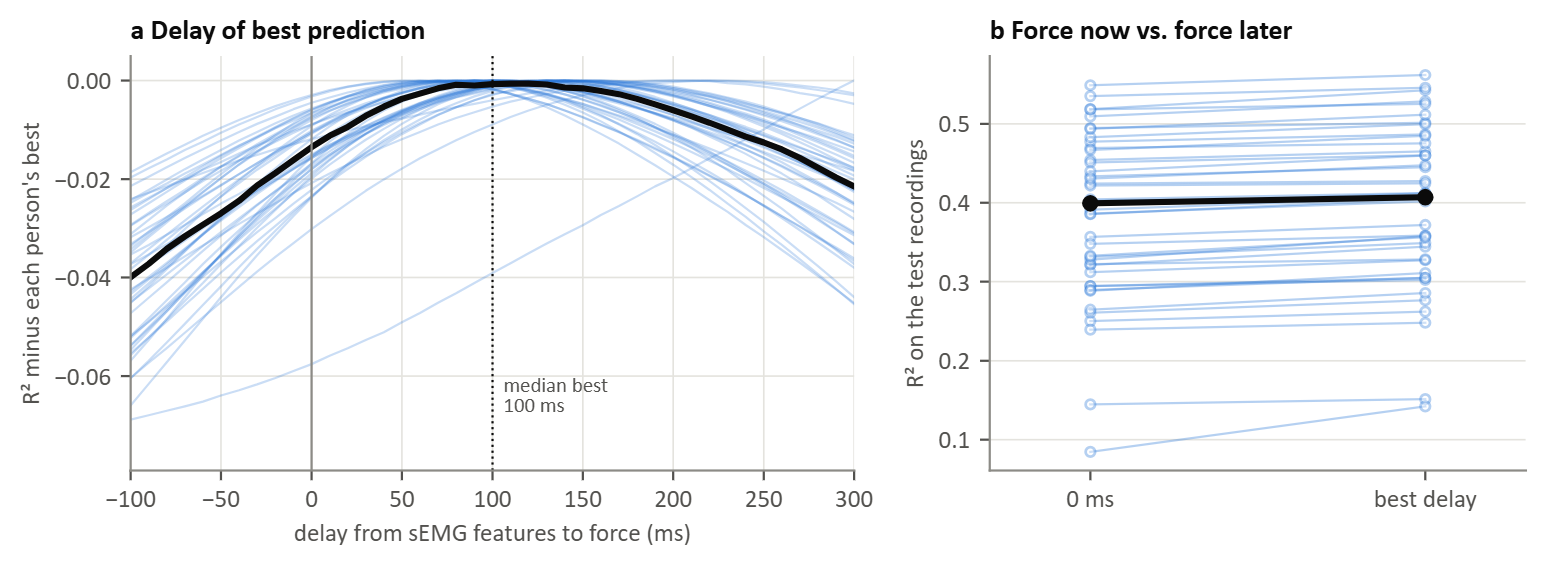

saved figures/figure9.png


In [9]:
OK = sorted(RES)
DP = np.array([RES[s]["delay_profile_r2"] for s in OK])
BEST_D = np.array([DELAYS_MS[int(np.argmax(v))] for v in DP])
i0 = DELAYS_MS.index(0)
r0, rb = DP[:, i0], DP.max(1)
print(f"delay of best prediction ({len(OK)} participants): median {np.median(BEST_D):.0f} ms, IQR [{np.percentile(BEST_D, 25):.0f}, {np.percentile(BEST_D, 75):.0f}] ms, "
      f"range {BEST_D.min()} to {BEST_D.max()} ms; after 0 ms in {int(np.sum(BEST_D > 0))} of {len(BEST_D)}")
print(f"R2 at 0 ms: median {np.median(r0):.2f}; at the best delay: median {np.median(rb):.2f}")
print("\nby finger (people whose best R2 for that finger is at least 0.2):")
FINGER_TIMING = {}
for f in FINGERS:
    V = np.array([RES[s]["delay_profile_r2_by_finger"][f] for s in OK])
    sel = V.max(1) >= 0.2
    bd = np.array([DELAYS_MS[int(np.argmax(v))] for v in V[sel]])
    FINGER_TIMING[f] = dict(people=int(sel.sum()), r2_best_median_all=round(float(np.median(V.max(1))), 3),
                            best_delay_median_ms=float(np.median(bd)) if len(bd) else None)
    print(f"  {f:12s} best R2 median {np.median(V.max(1)):.2f} | {sel.sum():2d} people with R2 >= 0.2"
          + (f", their best delay median {np.median(bd):.0f} ms" if len(bd) else ""))

fig, axs = plt.subplots(1, 2, figsize=(7.8, 2.9), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axs[0]
for v in DP:
    ax.plot(DELAYS_MS, v - v.max(), color=BLUE, alpha=0.25, lw=0.8)
ax.plot(DELAYS_MS, np.median(DP - DP.max(1, keepdims=True), 0), color=INK, lw=2.2)
ax.axvline(np.median(BEST_D), color=INK, lw=0.8, ls=":")
ax.axvline(0, color=MUTED, lw=0.8)
lo = max(-0.2, min(-0.05, 1.15 * float((DP - DP.max(1, keepdims=True)).min())))
ax.text(np.median(BEST_D) + 6, 0.85 * lo, f"median best\n{np.median(BEST_D):.0f} ms", fontsize=7.5, color=INK2)
ax.set_xlim(min(DELAYS_MS), max(DELAYS_MS)); ax.set_ylim(lo, 0.005)
ax.set_xlabel("delay from sEMG features to force (ms)"); ax.set_ylabel("R² minus each person's best")
ax.set_title("a  Delay of best prediction")
ax = axs[1]
for a0, ab in zip(r0, rb):
    ax.plot([0, 1], [a0, ab], color=BLUE, alpha=0.35, lw=0.8, marker="o", ms=3.5, mfc="white")
ax.plot([0, 1], [np.median(r0), np.median(rb)], color=INK, lw=2.2, marker="o", ms=5)
ax.set_xticks([0, 1]); ax.set_xticklabels(["0 ms", "best delay"]); ax.set_xlim(-0.3, 1.3)
ax.set_ylabel("R² on the test recordings"); ax.grid(axis="x", visible=False)
ax.set_title("b  Force now vs. force later")
fig.tight_layout(w_pad=1.2)
save(fig, "figure9.png")

## Figure 10 · Press detection

Each point is one detector setting (threshold 3, 5 or 8 SD above rest; confirmation 10, 25 or 50 ms), median across participants. **a.** Presses caught against false alarms per minute at rest (settings with no false alarms are drawn at 0.05); the dotted line is what a detector firing at random at that rate would catch in the same windows. **b.** Warning time: force onset minus the first firing (positive = before force; people with at least 5 caught presses). **c.** Presses caught by press type at 5 SD and 25 ms (mean across participants).

same day: setting | caught (median, IQR) | by chance | caught before force onset | false alarms/min | warning ms (people)
  k3_c10  | 82% [75%, 88%] | 52% | 13% | 14.84 | -169.25 (44)
  k3_c25  | 62% [54%, 72%] | 22% | 3% |  4.85 | -326.0 (44)
  k3_c50  | 44% [35%, 55%] | 7% | 1% |  1.52 | -452.0 (44)
  k5_c10  | 46% [34%, 55%] | 8% | 2% |  1.61 | -418.25 (44)
  k5_c25  | 30% [24%, 40%] | 2% | 0% |  0.44 | -540.0 (43)
  k5_c50  | 18% [10%, 25%] | 1% | 0% |  0.21 | -823.25 (40)
  k8_c10  | 15% [7%, 21%] | 0% | 0% |  0.00 | -774.5 (35)
  k8_c25  | 8% [2%, 14%] | 0% | 0% |  0.00 | -971.75 (26)
  k8_c50  | 2% [0%, 6%] | 0% | 0% |  0.00 | -1236.0 (15)

next session: setting | caught (median, IQR) | by chance | caught before force onset | false alarms/min | warning ms (people)
  k3_c10  | 73% [55%, 88%] | 52% | 11% | 14.88 | -179.0 (42)
  k3_c25  | 57% [36%, 69%] | 19% | 2% |  4.55 | -329.5 (42)
  k3_c50  | 38% [21%, 50%] | 8% | 0% |  1.65 | -469.5 (40)
  k5_c10  | 43% [29%, 58%] | 9% | 0% |

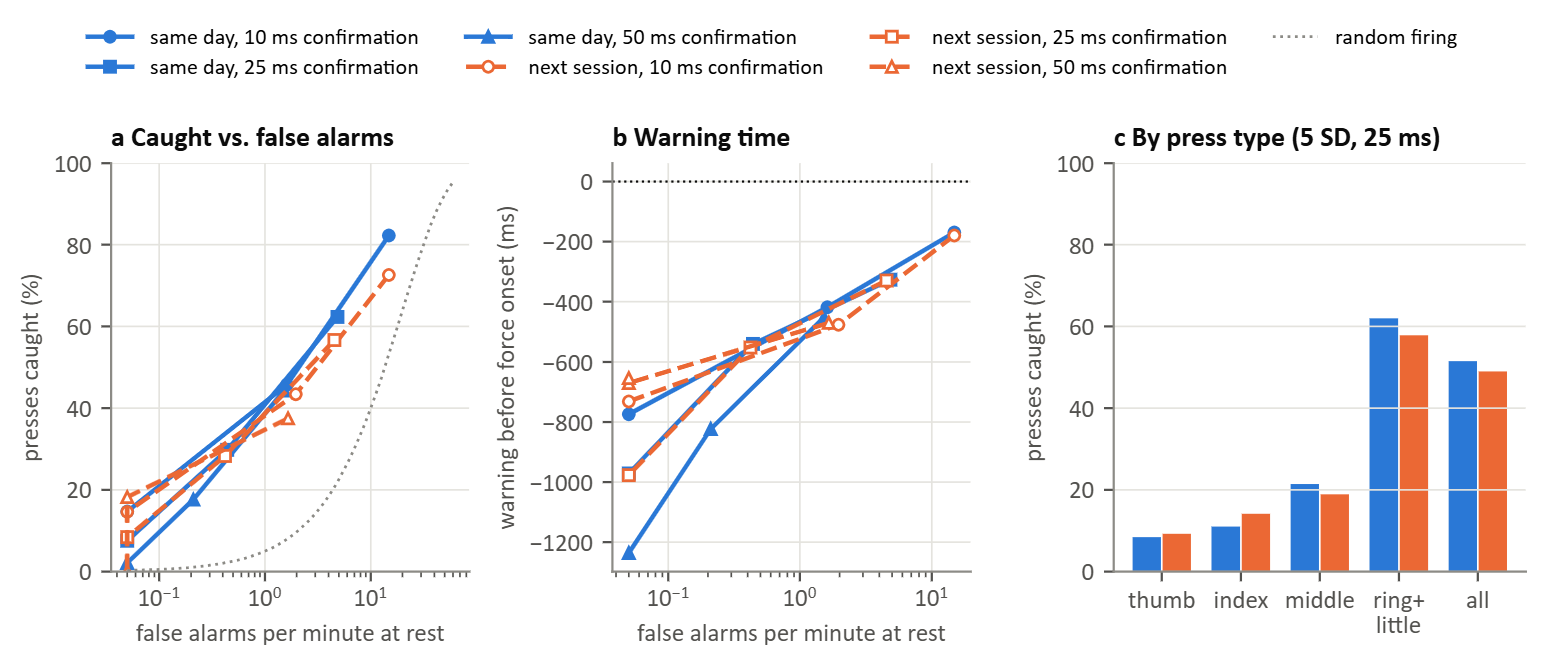

saved figures/figure10.png


In [10]:
SETTINGS = [f"k{k}_c{c}" for k in DET_K for c in DET_CONF_MS]
CONDS = [("detection_same_day", "same day"), ("detection_next_session", "next session")]
DET = {}
for cond, name in CONDS:
    DET[cond] = {}
    print(f"{name}: setting | caught (median, IQR) | by chance | caught before force onset | false alarms/min | warning ms (people)")
    for key in SETTINGS:
        V = [RES[s][cond][key] for s in OK if RES[s][cond]]
        ca = np.array([v["caught"] for v in V])
        cb = np.array([v["caught_before_force"] for v in V])
        fa = np.array([v["false_alarms_per_min"] for v in V])
        ch = 1 - np.exp(-fa / 60 * np.array([v["window_s_mean"] for v in V]))
        wa = np.array([v["warning_ms_median"] for v in V if v["warning_ms_median"] is not None and v["caught"] * v["presses"] >= 5])
        DET[cond][key] = dict(people=len(V), caught_median=round(float(np.median(ca)), 3),
                              caught_iqr=[round(float(np.percentile(ca, 25)), 3), round(float(np.percentile(ca, 75)), 3)],
                              caught_by_chance_median=round(float(np.median(ch)), 3),
                              caught_before_force_median=round(float(np.median(cb)), 3),
                              false_alarms_per_min_median=round(float(np.median(fa)), 2),
                              warning_ms_median=float(np.median(wa)) if len(wa) else None, warning_people=int(len(wa)),
                              caught_by_type_mean={t: round(float(np.mean([v["caught_by_type"][t] for v in V if v["caught_by_type"][t] is not None])), 3)
                                                   for t in PRESS_TYPES})
        d = DET[cond][key]
        print(f"  {key:7s} | {d['caught_median']:.0%} [{d['caught_iqr'][0]:.0%}, {d['caught_iqr'][1]:.0%}] | {d['caught_by_chance_median']:.0%} | "
              f"{d['caught_before_force_median']:.0%} | {d['false_alarms_per_min_median']:5.2f} | "
              f"{d['warning_ms_median'] if d['warning_ms_median'] is not None else '-'} ({d['warning_people']})")
    print()
WINDOW_S = float(np.median([RES[s]["detection_same_day"]["k5_c25"]["window_s_mean"] for s in OK]))
print(f"median window per press (300 ms before force onset to the end of the press): {WINDOW_S:.2f} s")

fig, axs = plt.subplots(1, 3, figsize=(7.8, 2.9), gridspec_kw=dict(width_ratios=[1, 1, 1.15]))
MK = {10: "o", 25: "s", 50: "^"}
for cond, name in CONDS:
    col, ls = (BLUE, "-") if cond.endswith("day") else (ORANGE, "--")
    for conf in DET_CONF_MS:
        keys = [f"k{k}_c{conf}" for k in DET_K]
        fa = np.maximum([DET[cond][k]["false_alarms_per_min_median"] for k in keys], 0.05)
        axs[0].plot(fa, [100 * DET[cond][k]["caught_median"] for k in keys], color=col, ls=ls, marker=MK[conf], ms=4,
                    mfc=col if cond.endswith("day") else "white", label=f"{name}, {conf} ms confirmation")
        w = [(f, DET[cond][k]["warning_ms_median"]) for f, k in zip(fa, keys) if DET[cond][k]["warning_ms_median"] is not None]
        if w:
            axs[1].plot(*zip(*w), color=col, ls=ls, marker=MK[conf], ms=4, mfc=col if cond.endswith("day") else "white")
xs = np.logspace(np.log10(0.05), np.log10(60), 60)
axs[0].plot(xs, 100 * (1 - np.exp(-xs / 60 * WINDOW_S)), color=MUTED, ls=":", lw=1, label="random firing")
for ax in axs[:2]:
    ax.set_xscale("log"); ax.set_xlabel("false alarms per minute at rest")
axs[0].set_ylabel("presses caught (%)"); axs[0].set_ylim(0, 100); axs[0].set_title("a  Caught vs. false alarms")
axs[1].axhline(0, color=INK, lw=0.8, ls=":"); axs[1].set_ylabel("warning before force onset (ms)")
axs[1].set_title("b  Warning time")
ax = axs[2]
x = np.arange(len(PRESS_TYPES))
for i, (cond, name) in enumerate(CONDS):
    ax.bar(x + (i - 0.5) * 0.38, [100 * DET[cond]["k5_c25"]["caught_by_type_mean"][t] for t in PRESS_TYPES], 0.36,
           color=BLUE if i == 0 else ORANGE, label=name)
ax.set_xticks(x); ax.set_xticklabels(["thumb", "index", "middle", "ring+\nlittle", "all"])
ax.set_ylabel("presses caught (%)"); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.set_title("c  By press type (5 SD, 25 ms)")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
save(fig, "figure10.png")

## Figure 11 · Forecast gain across participants

Error reduction of the sEMG forecast against baseline 1, one thin line per person, pooled over the four fingers and both sessions. Thick line: median. The table counts the people whose own 95% interval lies above or below zero, and tests the median gain across people (Wilcoxon signed-rank).

baseline 1: own estimate minus sEMG forecast (points of a typical press)
  rising     30 ms  -0.0 (8+/8-, p=0.970)   50 ms  +0.1 (19+/5-, p=0.002)   70 ms  +0.2 (26+/3-, p=0.000)  100 ms  +0.4 (37+/0-, p=0.000)  150 ms  +0.5 (39+/0-, p=0.000)  200 ms  +0.6 (40+/0-, p=0.000)
  steady     30 ms  +0.0 (30+/2-, p=0.000)   50 ms  +0.1 (32+/3-, p=0.000)   70 ms  +0.1 (32+/3-, p=0.000)  100 ms  +0.1 (31+/3-, p=0.000)  150 ms  +0.1 (27+/4-, p=0.000)  200 ms  +0.1 (25+/6-, p=0.001)
  falling    30 ms  -0.3 (0+/43-, p=0.000)   50 ms  -0.3 (0+/41-, p=0.000)   70 ms  -0.2 (1+/31-, p=0.000)  100 ms  -0.1 (3+/15-, p=0.009)  150 ms  +0.2 (17+/5-, p=0.000)  200 ms  +0.3 (26+/3-, p=0.000)

baseline 2: measured force minus sEMG forecast (points of a typical press)
  rising     30 ms -18.8 (0+/44-, p=0.000)   50 ms -13.6 (0+/44-, p=0.000)   70 ms  -9.7 (0+/41-, p=0.000)  100 ms  -6.0 (2+/36-, p=0.000)  150 ms  -1.8 (7+/18-, p=0.013)  200 ms  +0.5 (12+/10-, p=0.733)
  steady     30 ms -33.1 (0+/44-, p=0.0

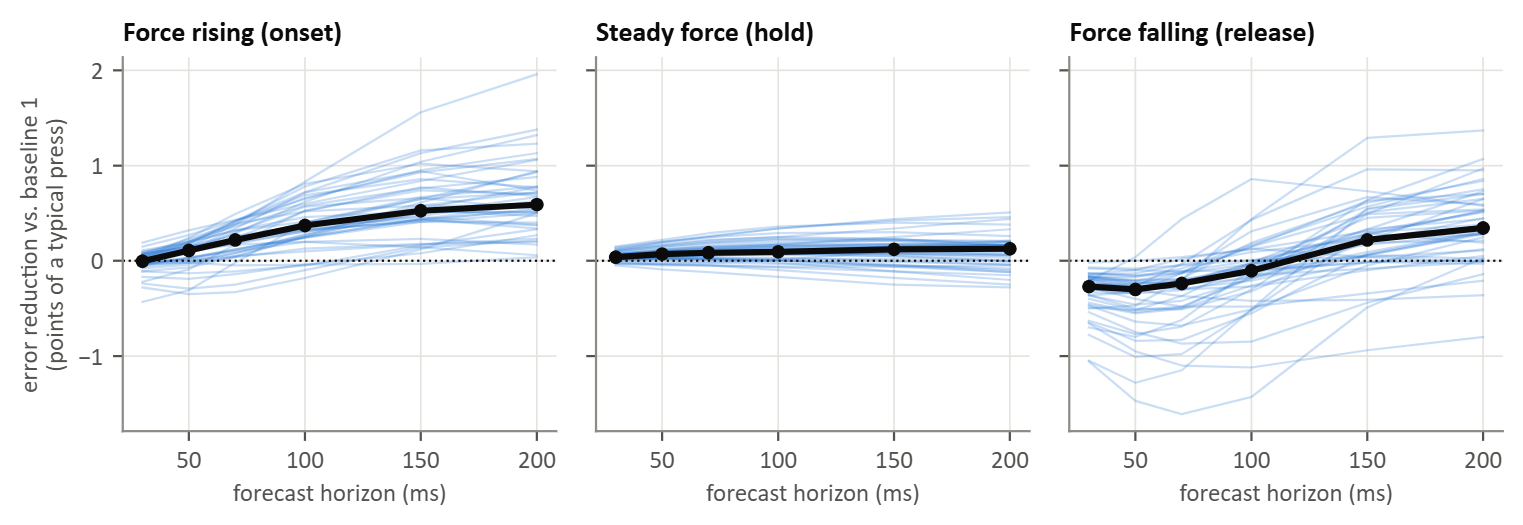

saved figures/figure11.png


In [11]:
GROUP = {}
for b in MODELS[1:]:
    GROUP[b] = {}
    print(f"{b} minus sEMG forecast (points of a typical press)")
    for p in PHASES:
        G = np.array([RES[s]["gain_points"][b][p]["gain"] for s in OK])
        LO = np.array([[c[0] for c in RES[s]["gain_points"][b][p]["ci95"]] for s in OK])
        HI = np.array([[c[1] for c in RES[s]["gain_points"][b][p]["ci95"]] for s in OK])
        rows = []
        for k, hm in enumerate(HORIZONS_MS):
            g = G[:, k][np.isfinite(G[:, k])]
            rows.append(dict(horizon_ms=hm, n=int(len(g)), median=round(float(np.median(g)), 2),
                             iqr=[round(float(np.percentile(g, 25)), 2), round(float(np.percentile(g, 75)), 2)],
                             people_above_zero=int(np.sum(LO[:, k] > 0)), people_below_zero=int(np.sum(HI[:, k] < 0)),
                             wilcoxon_p=round(float(wilcoxon(g).pvalue), 4)))
        GROUP[b][p] = rows
        print(f"  {p:8s}" + "".join(f"  {r['horizon_ms']:>3} ms {r['median']:+5.1f} ({r['people_above_zero']}+/{r['people_below_zero']}-, p={r['wilcoxon_p']:.3f})" for r in rows))
    print()
print("gain against baseline 1 by finger, force rising (median across people):")
BY_FINGER = {}
for f in FINGERS:
    G = np.array([RES[s]["gain_points"]["baseline 1: own estimate"]["rising"]["per_finger"][f] for s in OK], dtype=float)
    BY_FINGER[f] = [round(float(v), 2) for v in np.nanmedian(G, 0)]
    print(f"  {f:12s}" + "".join(f"  {hm:>3} ms {v:+5.1f}" for hm, v in zip(HORIZONS_MS, BY_FINGER[f])))

fig, axs = plt.subplots(1, 3, figsize=(7.8, 2.7), sharey=True)
for ax, p, title in zip(axs, PHASES, ["Force rising (onset)", "Steady force (hold)", "Force falling (release)"]):
    G = np.array([RES[s]["gain_points"]["baseline 1: own estimate"][p]["gain"] for s in OK])
    for g in G:
        ax.plot(HORIZONS_MS, g, color=BLUE, alpha=0.25, lw=0.8)
    ax.plot(HORIZONS_MS, np.nanmedian(G, 0), color=INK, lw=2.2, marker="o", ms=4)
    ax.axhline(0, color=INK, lw=0.8, ls=":")
    ax.set_title(title); ax.set_xlabel("forecast horizon (ms)"); ax.set_xticks([50, 100, 150, 200])
axs[0].set_ylabel("error reduction vs. baseline 1\n(points of a typical press)")
fig.tight_layout()
save(fig, "figure11.png")

## Figure 12 · Day-to-day transfer

R² on session 2 `repeats_short` for the finger force estimate (h = 0) and the forecast at 100 ms, mean over the four fingers. Median across participants.

participants with two sessions: 43

Force estimate (h = 0): median R2 (IQR)
  same_day                  0.463  [ 0.361,  0.543]
  previous_day             -0.752  [-1.595, -0.193]
  renormalised_20s         -0.329  [-0.717,  0.005]
  both_days_20s            -0.121  [-0.339,  0.122]
  new_day_only_20s          0.203  [ 0.111,  0.289]
  renormalised_40s         -0.415  [-0.805, -0.065]
  both_days_40s            -0.026  [-0.171,  0.185]
  new_day_only_40s          0.255  [ 0.157,  0.346]
  renormalised_60s         -0.384  [-0.681,  0.017]
  both_days_60s             0.061  [-0.092,  0.239]
  new_day_only_60s          0.307  [ 0.165,  0.401]
  renormalised_120s        -0.440  [-0.752,  0.013]
  both_days_120s            0.153  [-0.013,  0.294]
  new_day_only_120s         0.356  [ 0.256,  0.423]

Forecast, 100 ms ahead: median R2 (IQR)
  same_day                  0.484  [ 0.376,  0.553]
  previous_day             -0.766  [-1.655, -0.217]
  renormalised_20s         -0.322  [-0.737, -0.013]

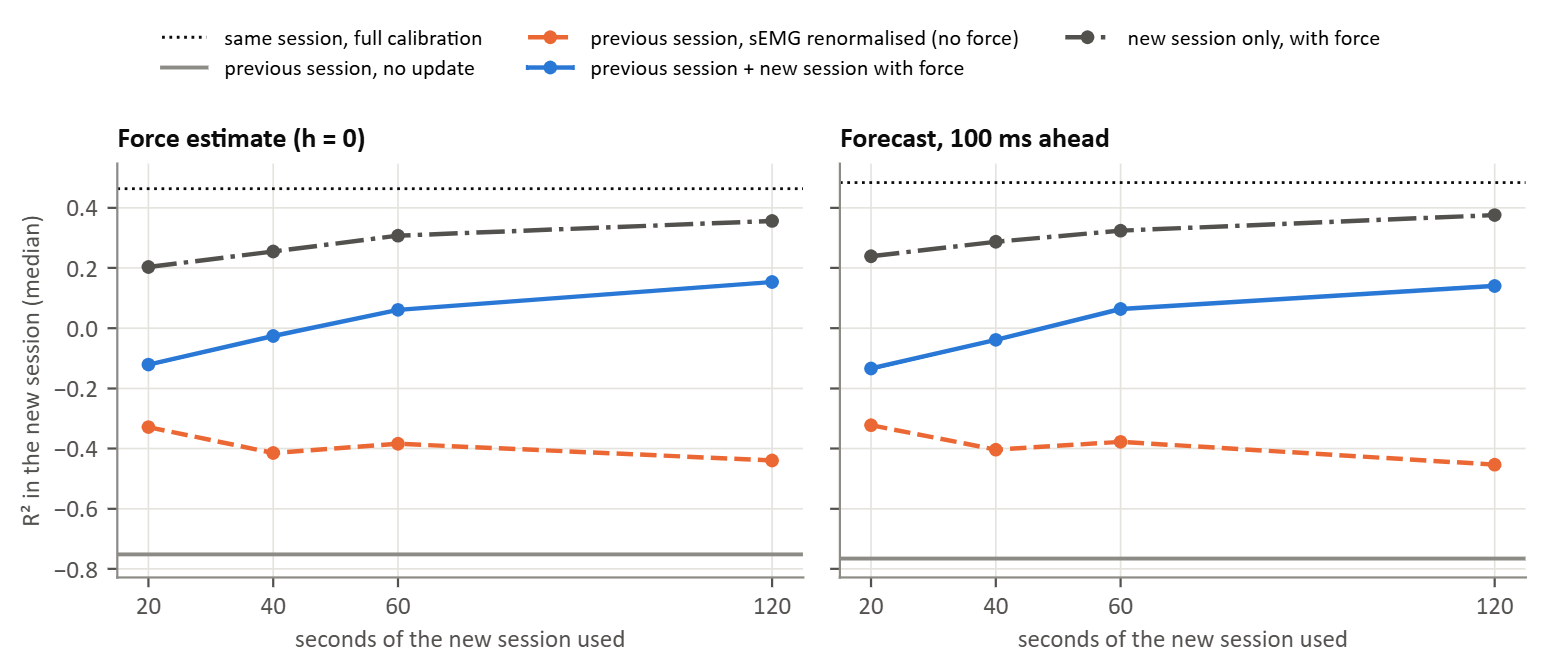

saved figures/figure12.png


In [12]:
OK2 = [s for s in OK if RES[s]["transfer_r2"]]
print(f"participants with two sessions: {len(OK2)}")
STRATS = [("renormalised", "previous session, sEMG renormalised (no force)", ORANGE, "--"),
          ("both_days", "previous session + new session with force", BLUE, "-"),
          ("new_day_only", "new session only, with force", INK2, "-.")]
TRANSFER = {}
fig, axs = plt.subplots(1, 2, figsize=(7.8, 2.9), sharey=True)
for ax, hk, title in zip(axs, ("h0", "h100"), ("Force estimate (h = 0)", "Forecast, 100 ms ahead")):
    T = {k: np.array([RES[s]["transfer_r2"][hk][k] for s in OK2]) for k in RES[OK2[0]]["transfer_r2"][hk]}
    TRANSFER[hk] = {k: dict(median=round(float(np.median(v)), 3), iqr=[round(float(np.percentile(v, 25)), 3), round(float(np.percentile(v, 75)), 3)])
                    for k, v in T.items()}
    ax.axhline(np.median(T["same_day"]), color=INK, lw=1, ls=":", label="same session, full calibration")
    ax.axhline(np.median(T["previous_day"]), color=MUTED, lw=1.4, label="previous session, no update")
    for key, lab, col, ls in STRATS:
        ax.plot(RECAL_S, [np.median(T[f"{key}_{sec}s"]) for sec in RECAL_S], color=col, ls=ls, marker="o", ms=4, label=lab)
    ax.set_title(title); ax.set_xlabel("seconds of the new session used"); ax.set_xticks(RECAL_S)
    print(f"\n{title}: median R2 (IQR)")
    for k, v in TRANSFER[hk].items():
        print(f"  {k:24s} {v['median']:6.3f}  [{v['iqr'][0]:6.3f}, {v['iqr'][1]:6.3f}]")
axs[0].set_ylabel("R² in the new session (median)")
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
save(fig, "figure12.png")

## Save the numbers

In [13]:
PERSON = {}
for s, r in RES.items():
    PERSON[str(s)] = dict(
        excluded_electrodes=len(r["excluded_electrodes"]),
        presses_with_force_onset=sum(v["with_force_onset"] for sess in r["presses"] for v in sess.values()),
        best_delay_ms=DELAYS_MS[int(np.argmax(r["delay_profile_r2"]))],
        r2_best_delay=max(r["delay_profile_r2"]), r2_zero_delay=r["delay_profile_r2"][DELAYS_MS.index(0)],
        detection_5sd_25ms=dict(same_day=r["detection_same_day"]["k5_c25"],
                                next_session=r["detection_next_session"]["k5_c25"] if r["detection_next_session"] else None),
        gain_vs_baseline1={p: r["gain_points"]["baseline 1: own estimate"][p]["gain"] for p in PHASES},
        transfer_r2=r["transfer_r2"])
OUT = dict(participants=OK, two_sessions=OK2,
           delay_of_best_prediction=dict(delays_ms=DELAYS_MS, median_ms=float(np.median(BEST_D)),
                                         iqr_ms=[float(np.percentile(BEST_D, 25)), float(np.percentile(BEST_D, 75))],
                                         r2_at_0_median=float(np.median(r0)), r2_at_best_median=float(np.median(rb)),
                                         by_finger=FINGER_TIMING),
           press_detection=DET, forecast_gain_group=GROUP, forecast_gain_by_finger_rising=BY_FINGER,
           transfer_r2_group=TRANSFER, per_participant=PERSON,
           settings=dict(horizons_ms=HORIZONS_MS, recalibration_s=list(RECAL_S), detector_k_sd=list(DET_K),
                         detector_confirmation_ms=list(DET_CONF_MS), bootstrap=N_BOOT, block_s=BLOCK / FS_F))
txt = json.dumps(OUT, indent=1)
txt = re.sub(r"\[\s+([^\[\]{}]*?)\s+\]", lambda m: "[" + re.sub(r"\s+", " ", m.group(1)) + "]", txt)
(RES_DIR / "putemg_force.json").write_text(txt + "\n")
print("saved results/putemg_force.json")

saved results/putemg_force.json
